# Lab 1 — Dataset A: Default of Credit Card Clients
Data: `lab1/data/raw/UCI_Credit_Card.csv` from [Kaggle](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset) (original: [UCI #350](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)). Figures → `lab1/figures/credit/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

SEED = 42
DATA = Path("../data/raw")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
FIG = Path("../figures/credit")
FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")


def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


def chi2_table(df, cols, target):
    rows = []
    for c in cols:
        table = pd.crosstab(df[c], df[target])
        chi2, p, _, _ = chi2_contingency(table)
        v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
        rows.append((c, df[c].mode()[0], round(chi2, 1), round(p, 4), round(v, 3)))
    return pd.DataFrame(rows, columns=["feature", "mode", "chi-square", "p-value", "Cramér's V"])

# Part 1 — Study the dataset
## 1.1 Load and describe

In [2]:
df_raw = pd.read_csv(DATA / "UCI_Credit_Card.csv")
df_raw = df_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"})  # PAY_0 -> PAY_1 for consistency

PAY = [f"PAY_{i}" for i in range(1, 7)]          # repayment status, Sep -> Apr 2005
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]     # bill amount
PAY_AMT = [f"PAY_AMT{i}" for i in range(1, 7)]   # amount paid
MONEY = ["LIMIT_BAL"] + BILL + PAY_AMT

print(df_raw.shape)
df_raw.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,"20,000.000",2,2,1,24,2,2,-1,-1,-2,-2,"3,913.000","3,102.000",689.000,0.000,0.000,0.000,0.000,689.000,0.000,0.000,0.000,0.000,1
1,2,"120,000.000",2,2,2,26,-1,2,0,0,0,2,"2,682.000","1,725.000","2,682.000","3,272.000","3,455.000","3,261.000",0.000,"1,000.000","1,000.000","1,000.000",0.000,"2,000.000",1
2,3,"90,000.000",2,2,2,34,0,0,0,0,0,0,"29,239.000","14,027.000","13,559.000","14,331.000","14,948.000","15,549.000","1,518.000","1,500.000","1,000.000","1,000.000","1,000.000","5,000.000",0
3,4,"50,000.000",2,2,1,37,0,0,0,0,0,0,"46,990.000","48,233.000","49,291.000","28,314.000","28,959.000","29,547.000","2,000.000","2,019.000","1,200.000","1,100.000","1,069.000","1,000.000",0
4,5,"50,000.000",1,2,1,57,-1,0,-1,0,0,0,"8,617.000","5,670.000","35,835.000","20,940.000","19,146.000","19,131.000","2,000.000","36,681.000","10,000.000","9,000.000",689.000,679.000,0


## 1.2 Feature types

In [3]:
pd.DataFrame([
    ("LIMIT_BAL", "Numerical", "Quantitative", "Continuous", "Credit limit (NT$)"),
    ("SEX", "Categorical, nominal", "Qualitative", "Discrete", "1 male, 2 female"),
    ("EDUCATION", "Categorical, ordinal", "Qualitative", "Discrete", "1 graduate, 2 university, 3 high school, 4 others"),
    ("MARRIAGE", "Categorical, nominal", "Qualitative", "Discrete", "1 married, 2 single, 3 others"),
    ("AGE", "Numerical", "Quantitative", "Discrete", "Years"),
    ("PAY_1..6", "Categorical, ordinal", "Qualitative", "Discrete", "-1 paid on time, 1..9 months of delay"),
    ("BILL_AMT1..6", "Numerical", "Quantitative", "Continuous", "Monthly bill (NT$)"),
    ("PAY_AMT1..6", "Numerical", "Quantitative", "Continuous", "Monthly payment (NT$)"),
    ("default", "Categorical, binary", "Qualitative", "Discrete", "LABEL: 1 = default next month"),
], columns=["feature", "numerical / categorical", "quantitative / qualitative", "discrete / continuous", "meaning"])

,feature,numerical / categorical,quantitative / qualitative,discrete / continuous,meaning
0,LIMIT_BAL,Numerical,Quantitative,Continuous,Credit limit (NT$)
1,SEX,"Categorical, nominal",Qualitative,Discrete,"1 male, 2 female"
2,EDUCATION,"Categorical, ordinal",Qualitative,Discrete,"1 graduate, 2 university, 3 high school, 4 others"
3,MARRIAGE,"Categorical, nominal",Qualitative,Discrete,"1 married, 2 single, 3 others"
4,AGE,Numerical,Quantitative,Discrete,Years
5,PAY_1..6,"Categorical, ordinal",Qualitative,Discrete,"-1 paid on time, 1..9 months of delay"
6,BILL_AMT1..6,Numerical,Quantitative,Continuous,Monthly bill (NT$)
7,PAY_AMT1..6,Numerical,Quantitative,Continuous,Monthly payment (NT$)
8,default,"Categorical, binary",Qualitative,Discrete,LABEL: 1 = default next month


## 1.3 Data quality issues

In [4]:
issues = pd.Series({
    "missing values": int(df_raw.isna().sum().sum()),
    "duplicate rows (ignoring ID)": int(df_raw.drop(columns="ID").duplicated().sum()),
    "EDUCATION code not in 1-4": int((~df_raw["EDUCATION"].isin([1, 2, 3, 4])).sum()),
    "MARRIAGE code not in 1-3": int((~df_raw["MARRIAGE"].isin([1, 2, 3])).sum()),
    "PAY_x = -2 or 0 (undocumented)": int(df_raw[PAY].isin([-2, 0]).sum().sum()),
    "negative BILL_AMT": int((df_raw[BILL] < 0).sum().sum()),
}, name="count")
issues.to_frame()

,count
missing values,0
duplicate rows (ignoring ID),35
EDUCATION code not in 1-4,345
MARRIAGE code not in 1-3,54
PAY_x = -2 or 0 (undocumented),120334
negative BILL_AMT,3932


In [5]:
outliers = df_raw[MONEY + ["AGE"]].apply(iqr_outliers).rename("IQR outliers").to_frame()
outliers["% rows"] = (outliers["IQR outliers"] / len(df_raw) * 100).round(1)
outliers

,IQR outliers,% rows
LIMIT_BAL,167,0.600
BILL_AMT1,2400,8.000
BILL_AMT2,2395,8.000
BILL_AMT3,2469,8.200
BILL_AMT4,2622,8.700
BILL_AMT5,2725,9.100
BILL_AMT6,2693,9.000
PAY_AMT1,2745,9.200
PAY_AMT2,2714,9.000
PAY_AMT3,2598,8.700


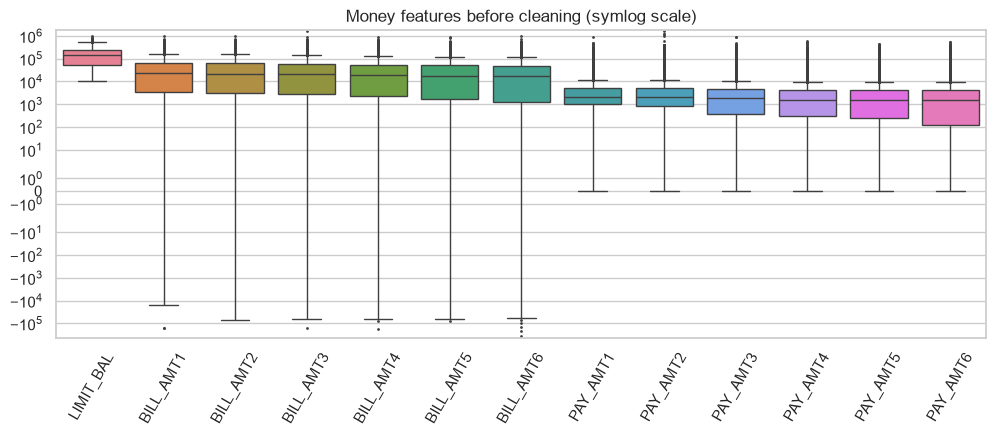

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df_raw[MONEY], ax=ax, fliersize=1)
ax.set_yscale("symlog")              # symlog: log scale that also handles negative bills
ax.tick_params(axis="x", rotation=60)
ax.set_title("Money features before cleaning (symlog scale)")
save(fig, "fig1_boxplots")

## 1.4 Data cleaning
- Drop `ID` and duplicate rows
- Unknown codes → "others": EDUCATION 0/5/6 → 4, MARRIAGE 0 → 3
- PAY_x: -2, -1, 0 all mean *no delay* → 0, so the feature becomes "months of delay"
- Negative bills are kept (customer overpaid, a real value)
- Outliers: money columns capped at the 1st / 99th percentile (winsorizing)

In [7]:
df = df_raw.drop(columns="ID")
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
df[PAY] = df[PAY].clip(lower=0)
df[MONEY] = df[MONEY].clip(df[MONEY].quantile(0.01), df[MONEY].quantile(0.99), axis=1)
df = df.drop_duplicates()                       # last, so rows that became identical are also removed

pd.DataFrame({
    "before": [len(df_raw), issues.iloc[1], issues.iloc[2], issues.iloc[3], issues.iloc[4], int(df_raw[MONEY].abs().max().max())],
    "after": [len(df), int(df.duplicated().sum()), int((~df["EDUCATION"].isin([1, 2, 3, 4])).sum()),
              int((~df["MARRIAGE"].isin([1, 2, 3])).sum()), int(df[PAY].isin([-2, -1]).sum().sum()), int(df[MONEY].abs().max().max())],
}, index=["rows", "duplicates", "bad EDUCATION codes", "bad MARRIAGE codes", "undocumented PAY codes", "largest money value"])

,before,after
rows,30000,29964
duplicates,35,0
bad EDUCATION codes,345,0
bad MARRIAGE codes,54,0
undocumented PAY codes,120334,0
largest money value,1684259,500000


Effect of cleaning on the signal and the tails:

In [8]:
from scipy.stats import skew
pd.DataFrame({
    "before": [df_raw["PAY_1"].corr(df_raw["default"]), skew(df_raw["PAY_AMT1"])],
    "after": [df["PAY_1"].corr(df["default"]), skew(df["PAY_AMT1"])],
}, index=["r(PAY_1, default)", "skewness of PAY_AMT1"]).round(3)

,before,after
"r(PAY_1, default)",0.325,0.396
skewness of PAY_AMT1,14.668,4.479


## 1.5 Data integration
Single source file, no other table shares a client ID → integration is not needed.

## 1.6 Data transformation
- **One-hot encoding** for SEX, MARRIAGE, EDUCATION (EDUCATION is no longer ordered once "others" is merged in)
- **Standardization (z-score)** for the 20 numeric features: money is in hundreds of thousands, PAY codes are 0-8, so without it money would dominate PCA

In [9]:
NOMINAL = ["SEX", "MARRIAGE", "EDUCATION"]
NUMERIC = ["LIMIT_BAL", "AGE"] + PAY + BILL + PAY_AMT          # 20 features used for statistics and PCA

df_encoded = pd.get_dummies(df, columns=NOMINAL, dtype=int)
X = pd.DataFrame(StandardScaler().fit_transform(df[NUMERIC]), columns=NUMERIC, index=df.index)

print("encoded shape:", df_encoded.shape)
pd.DataFrame({"mean before": df[NUMERIC].mean(), "std before": df[NUMERIC].std(),
              "mean after": X.mean(), "std after": X.std()}).round(2).head(6)

encoded shape: (29964, 30)


,mean before,std before,mean after,std after
LIMIT_BAL,"166,765.110","127,596.490",-0.000,1.000
AGE,35.490,9.220,0.000,1.000
PAY_1,0.360,0.760,-0.000,1.000
PAY_2,0.320,0.800,0.000,1.000
PAY_3,0.300,0.790,0.000,1.000
PAY_4,0.260,0.760,0.000,1.000


## 1.7 Label
`default` (0/1) → **binary classification**.

In [10]:
print(df["default"].value_counts())
print(f"default rate: {df['default'].mean() * 100:.1f}%")

default
0    23334
1     6630
Name: count, dtype: int64
default rate: 22.1%


## 1.8 Statistics
Numeric: mean, variance (pandas uses n-1), covariance, correlation. Categorical: frequencies + chi-square / Cramér's V against the label.

In [11]:
pd.DataFrame({"mean": df[NUMERIC].mean(), "variance": df[NUMERIC].var()})

,mean,variance
LIMIT_BAL,"166,765.107","16,280,864,259.705"
AGE,35.488,84.998
PAY_1,0.356,0.579
PAY_2,0.320,0.643
PAY_3,0.304,0.625
PAY_4,0.259,0.579
PAY_5,0.222,0.515
PAY_6,0.227,0.512
BILL_AMT1,"50,483.700","4,805,868,391.928"
BILL_AMT2,"48,438.426","4,465,219,011.171"


In [12]:
cov = df[NUMERIC].cov()
corr = df[NUMERIC].corr()
cov.iloc[:6, :6]          # first 6 features, full matrix: cov

,LIMIT_BAL,AGE,PAY_1,PAY_2,PAY_3,PAY_4
LIMIT_BAL,"16,280,864,259.705","170,084.304","-16,739.958","-20,351.309","-19,464.481","-17,677.485"
AGE,"170,084.304",84.998,-0.010,-0.065,-0.103,-0.050
PAY_1,"-16,739.958",-0.010,0.579,0.426,0.311,0.267
PAY_2,"-20,351.309",-0.065,0.426,0.643,0.421,0.313
PAY_3,"-19,464.481",-0.103,0.311,0.421,0.625,0.408
PAY_4,"-17,677.485",-0.050,0.267,0.313,0.408,0.579


In [13]:
for c in NOMINAL:
    display(df[c].value_counts(normalize=True).round(3).to_frame(c))
chi2_table(df, NOMINAL, "default")

,SEX
SEX,
2,0.604
1,0.396


,MARRIAGE
MARRIAGE,
2,0.532
1,0.455
3,0.013


,EDUCATION
EDUCATION,
2,0.468
1,0.353
3,0.164
4,0.016


,feature,mode,chi-square,p-value,Cramér's V
0,SEX,2,47.100,0.000,0.040
1,MARRIAGE,2,27.500,0.000,0.030
2,EDUCATION,2,160.500,0.000,0.073


In [14]:
# default rate per category
pay_group = pd.cut(df["PAY_1"], [-1, 0, 1, 2, 99], labels=["0", "1", "2", ">=3"])
rates = {"PAY_1 (months of delay)": df.groupby(pay_group, observed=True)["default"].mean()}
for c in NOMINAL:
    rates[c] = df.groupby(c)["default"].mean()
pd.concat(rates).mul(100).round(1).to_frame("default rate %")

default rate %
PAY_1 (months of delay) 0            13.800
                        1            34.000
                        2            69.100
                        >=3          71.900
SEX                     1            24.200
                        2            20.800
MARRIAGE                1            23.500
                        2            20.900
                        3            23.600
EDUCATION               1            19.200
                        2            23.700
                        3            25.200
                        4             7.100

## 1.9 Correlation

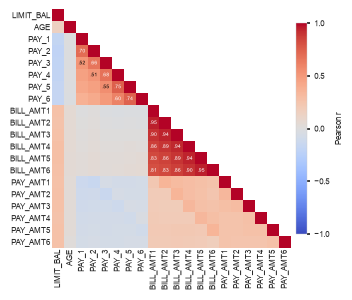

,,r
BILL_AMT1,BILL_AMT2,0.952
BILL_AMT5,BILL_AMT6,0.948
BILL_AMT4,BILL_AMT5,0.942
BILL_AMT2,BILL_AMT3,0.941
BILL_AMT3,BILL_AMT4,0.936


In [15]:
n = len(corr)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(3.4, 3.1))
im = ax.imshow(np.ma.array(corr.values, mask=mask), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5.6)
ax.set_yticks(range(n)); ax.set_yticklabels(corr.index, fontsize=5.6)
ax.tick_params(length=0, pad=1.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(n):
    for j in range(i):
        r = corr.values[i, j]
        if abs(r) >= 0.5:
            ax.text(j, i, f"{r:.2f}".replace("0.", "."), ha="center", va="center",
                    fontsize=3.9, color="white" if abs(r) > 0.6 else "black")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
cb.ax.grid(False); cb.outline.set_linewidth(0.3)
cb.ax.tick_params(labelsize=5.6, length=2); cb.set_label("Pearson r", fontsize=6.1)
fig.savefig(FIG / "fig2_corr_credit.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
top = pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5)
top.round(3).to_frame("r")

In [16]:
bill_r = [corr.loc[f"BILL_AMT{i}", f"BILL_AMT{i + 1}"] for i in range(1, 6)]
pay_r = corr.loc[PAY, PAY].to_numpy()[np.triu_indices(6, 1)]
print(f"bills, adjacent months: r = {min(bill_r):.3f} to {max(bill_r):.3f}")
print(f"repayment codes block:  r = {pay_r.min():.2f} to {pay_r.max():.2f}")

bills, adjacent months: r = 0.936 to 0.952
repayment codes block:  r = 0.37 to 0.75


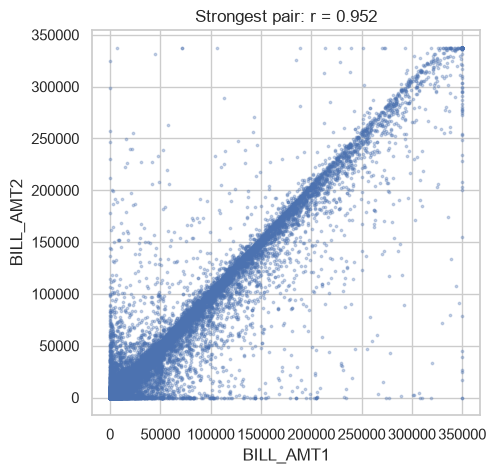

In [17]:
a, b = top.index[0]
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df[a], df[b], s=3, alpha=0.3)
ax.set(xlabel=a, ylabel=b, title=f"Strongest pair: r = {corr.loc[a, b]:.3f}")
save(fig, "fig3_strongest_pair")

# Part 2 — PCA

## 2.1 Apply PCA
Input = standardized features `X` (label removed). Steps from slide 27: centre → covariance matrix → eigenvectors sorted by eigenvalue → project.

In [18]:
C = np.cov(X.to_numpy().T)                      # covariance matrix (X is already centred)
eigvals, eigvecs = np.linalg.eigh(C)
eigvals = eigvals[np.argsort(eigvals)[::-1]]       # sort by eigenvalue, largest first

pca = PCA(random_state=SEED).fit(X)                 # keep all components
Z = pca.transform(X)                                # projected data
print("Manual eigenvalues == sklearn:", np.allclose(eigvals, pca.explained_variance_))

Manual eigenvalues == sklearn: True


Why standardize: PCA on the **unscaled** features.

In [19]:
raw = df[NUMERIC]
pca_raw = PCA(random_state=SEED).fit(raw)
top_feature = raw.columns[np.abs(pca_raw.components_[0]).argmax()]
print(f"unscaled PC1 explains {pca_raw.explained_variance_ratio_[0] * 100:.1f}% and is dominated by {top_feature}")

unscaled PC1 explains 61.5% and is dominated by LIMIT_BAL


## 2.2 Explained variance

In [20]:
ev = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "explained %": pca.explained_variance_ratio_ * 100,
    "cumulative %": np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=[f"PC{i}" for i in range(1, pca.n_components_ + 1)]).round(2)

k_for = {t: int(np.argmax(ev["cumulative %"].to_numpy() >= t) + 1) for t in (80, 90, 95)}
print("PCs needed:", {f"{t}%": k for t, k in k_for.items()})
print("Kaiser rule (eigenvalue > 1):", int((ev["eigenvalue"] > 1).sum()), "PCs")
print(f"ratio largest / smallest eigenvalue: {pca.explained_variance_[0] / pca.explained_variance_[-1]:.0f}")
ev

PCs needed: {'80%': 8, '90%': 11, '95%': 13}
Kaiser rule (eigenvalue > 1): 4 PCs
ratio largest / smallest eigenvalue: 265


,eigenvalue,explained %,cumulative %
PC1,6.190,30.930,30.930
PC2,3.960,19.800,50.720
PC3,1.760,8.820,59.540
PC4,1.030,5.140,64.680
PC5,0.960,4.790,69.470
PC6,0.820,4.080,73.550
PC7,0.790,3.960,77.500
PC8,0.740,3.710,81.210
PC9,0.730,3.640,84.860
PC10,0.690,3.470,88.330


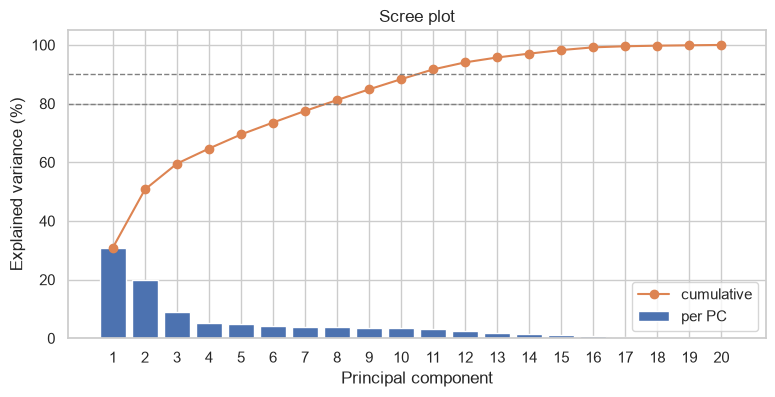

In [21]:
x = np.arange(1, len(ev) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x, ev["explained %"], label="per PC")
ax.plot(x, ev["cumulative %"], "o-", color="C1", label="cumulative")
for t in (80, 90):
    ax.axhline(t, ls="--", c="gray", lw=1)
ax.set(xlabel="Principal component", ylabel="Explained variance (%)", xticks=x, title="Scree plot")
ax.legend()
save(fig, "fig4_explained_variance")

## 2.3 Highest vs lowest variance components
Same axis scale on both plots: the last PCs barely move.

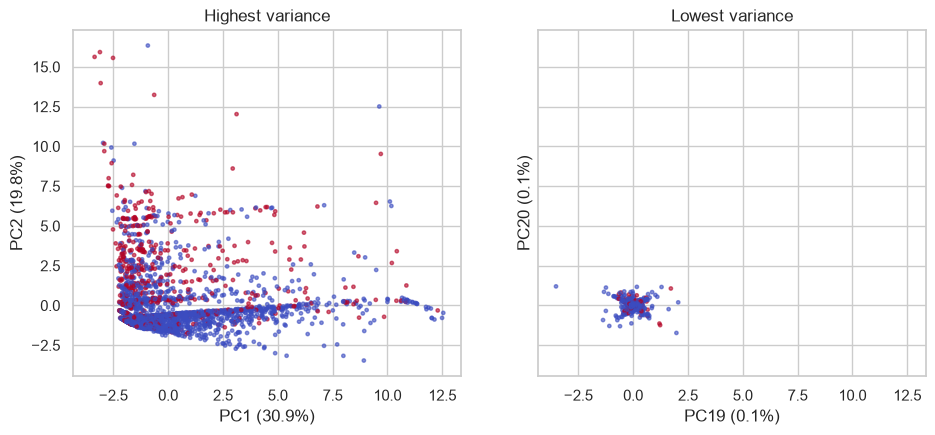

In [22]:
sample = np.random.default_rng(SEED).choice(len(Z), min(3000, len(Z)), replace=False)  # fewer points = readable plot
y = df["default"].to_numpy()
d = Z.shape[1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, (i, j) in zip(axes, [(0, 1), (d - 2, d - 1)]):
    ax.scatter(Z[sample, i], Z[sample, j], c=y[sample], cmap="coolwarm", s=6, alpha=0.6)
    ax.set(xlabel=f"PC{i + 1} ({pca.explained_variance_ratio_[i] * 100:.1f}%)",
           ylabel=f"PC{j + 1} ({pca.explained_variance_ratio_[j] * 100:.1f}%)")
axes[0].set_title("Highest variance")
axes[1].set_title("Lowest variance")
save(fig, "fig5_high_vs_low_pcs")

Spread (standard deviation) and meaning of the last two PCs.

In [23]:
sd = np.sqrt(pca.explained_variance_)
print(f"std PC1 = {sd[0]:.2f}, PC{d - 1} = {sd[-2]:.2f}, PC{d} = {sd[-1]:.2f}")
last = pd.DataFrame(pca.components_[-2:].T, index=X.columns, columns=[f"PC{d - 1}", f"PC{d}"])
last[last.abs().max(axis=1) > 0.2].round(2)          # features that build the last PCs

std PC1 = 2.49, PC19 = 0.16, PC20 = 0.15


,PC19,PC20
BILL_AMT1,-0.300,0.200
BILL_AMT2,0.570,-0.440
BILL_AMT3,-0.290,0.470
BILL_AMT4,-0.190,-0.490
BILL_AMT5,0.560,0.490
BILL_AMT6,-0.350,-0.230


In [24]:
pc2_by_class = pd.Series(Z[:, 1]).groupby(y).mean().round(2)
pc2_by_class.index = ['No default', 'Default']
pc2_by_class.to_frame("mean PC2 score")

,mean PC2 score
No default,-0.400
Default,1.400


## 2.4 Varying the number of components k

In [25]:
rows = []
for k in range(1, X.shape[1] + 1):
    p = PCA(n_components=k, random_state=SEED).fit(X)
    X_back = p.inverse_transform(p.transform(X))            # reconstruct (slide 33)
    rows.append({"k": k,
                 "variance kept %": p.explained_variance_ratio_.sum() * 100,
                 "reconstruction MSE": np.mean((X.to_numpy() - X_back) ** 2),
                 "dimensions removed %": (1 - k / X.shape[1]) * 100})
vary = pd.DataFrame(rows).round(3)
# standardized inputs: reconstruction MSE = share of variance discarded
print("MSE == 1 - variance kept:", np.allclose(vary["reconstruction MSE"], 1 - vary["variance kept %"] / 100, atol=1e-3))
vary

MSE == 1 - variance kept: True


,k,variance kept %,reconstruction MSE,dimensions removed %
0,1,30.926,0.691,95.000
1,2,50.722,0.493,90.000
2,3,59.538,0.405,85.000
3,4,64.679,0.353,80.000
4,5,69.470,0.305,75.000
5,6,73.547,0.265,70.000
6,7,77.503,0.225,65.000
7,8,81.212,0.188,60.000
8,9,84.855,0.151,55.000
9,10,88.330,0.117,50.000


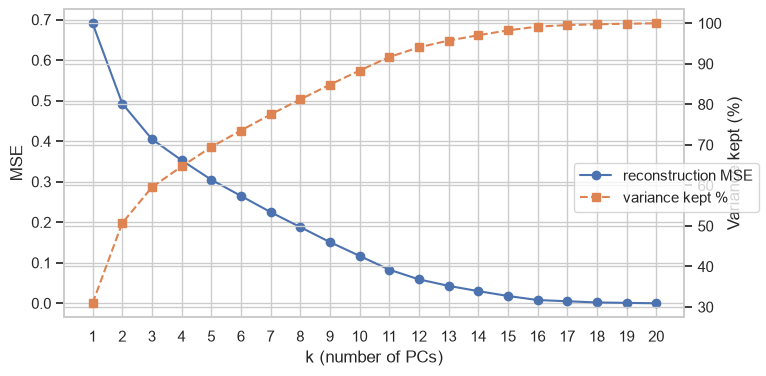

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(vary["k"], vary["reconstruction MSE"], "o-", label="reconstruction MSE")
ax2 = ax.twinx()
ax2.plot(vary["k"], vary["variance kept %"], "s--", color="C1", label="variance kept %")
ax.set(xlabel="k (number of PCs)", ylabel="MSE", xticks=vary["k"])
ax2.set_ylabel("Variance kept (%)")
fig.legend(loc="center right")
save(fig, "fig6_vary_k")

## 2.5 2D visualization (PC1 vs PC2)

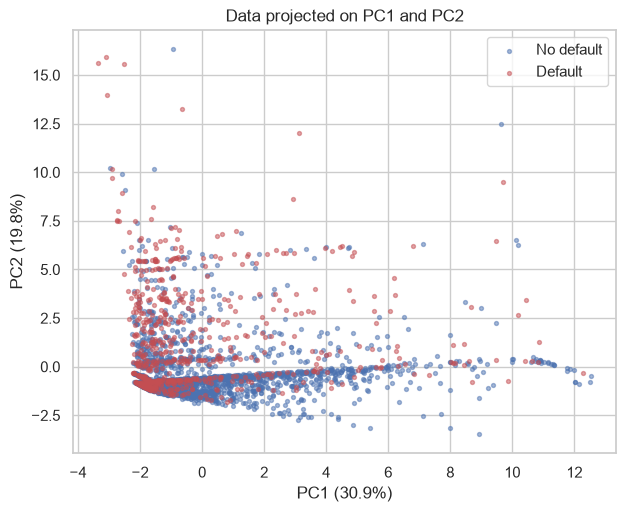

In [27]:
r = pca.explained_variance_ratio_ * 100
fig, ax = plt.subplots(figsize=(7, 5.5))
for value, name, color in [(0, "No default", "C0"), (1, "Default", "C3")]:
    m = sample[y[sample] == value]
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, c=color, label=name)
ax.set(xlabel=f"PC1 ({r[0]:.1f}%)", ylabel=f"PC2 ({r[1]:.1f}%)", title="Data projected on PC1 and PC2")
ax.legend()
save(fig, "fig7_pca_2d")

## 2.6 Original vs PCA representation
Loadings = weight of each original feature in a PC (how to interpret a PC).

,PC1,PC2,PC3
BILL_AMT4,0.377,0.076,-0.136
BILL_AMT3,0.375,0.069,-0.166
BILL_AMT5,0.374,0.082,-0.117
BILL_AMT2,0.368,0.065,-0.196
BILL_AMT6,0.366,0.083,-0.105
BILL_AMT1,0.358,0.057,-0.209
PAY_AMT1,0.173,-0.075,0.311
LIMIT_BAL,0.173,-0.143,0.252
PAY_AMT2,0.163,-0.077,0.338
PAY_AMT3,0.156,-0.075,0.361


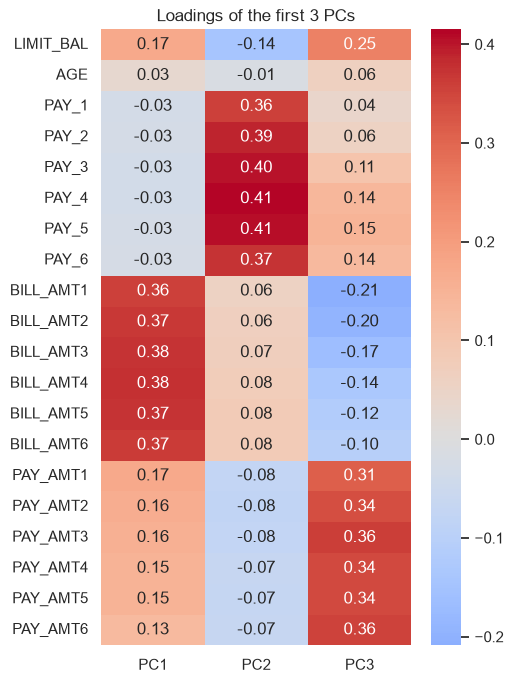

In [28]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])

fig, ax = plt.subplots(figsize=(5, 0.35 * len(loadings) + 1))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Loadings of the first 3 PCs")
save(fig, "fig8_loadings")

loadings.round(3).sort_values("PC1", key=abs, ascending=False)

In [29]:
k = k_for[90]
pd.DataFrame({
    "Original": [X.shape[1], "100%", "Yes, each column is a real feature"],
    f"PCA (k = {k})": [k, f"{ev['cumulative %'].iloc[k - 1]:.1f}%", "Harder, each PC mixes all features"],
}, index=["Dimensions", "Variance kept", "Interpretable"])

,Original,PCA (k = 11)
Dimensions,20,11
Variance kept,100%,91.7%
Interpretable,"Yes, each column is a real feature","Harder, each PC mixes all features"


## 2.7 Separability: original vs PCA
Can a linear model still tell the classes apart? Class-weighted logistic regression, balanced accuracy, 5-fold stratified CV (chance = 50%).

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
model = LogisticRegression(class_weight="balanced", max_iter=2000)
inputs = {"all 20 original features": X, "PC1 + PC2": Z[:, :2]}
pd.Series({name: cross_val_score(model, data, df["default"], cv=cv, scoring="balanced_accuracy").mean() * 100
           for name, data in inputs.items()}, name="balanced accuracy %").round(1).to_frame()

,balanced accuracy %
all 20 original features,70.100
PC1 + PC2,68.800
